# NETDEFY — Notebook 02: Data Quality, Deduplication & Ambiguity Tracking

**Project:** NETDEFY — Network Defense Intelligence  
**Notebook:** `notebooks/02_data_quality_analysis.ipynb`  
**Purpose:** Forensic audit of missing values, infinities, physical duplicate records, feature-only deduplication, conflicting ground-truth labels, and benchmark ambiguity tracking.  
**Historical Provenance:** Phase 2 Forensic Inspection, Phase 3 Preprocessing, Phase 3.1 Duplicate Policy & Label Integrity Audit (`reports/PHASE3_1_DUPLICATE_LABEL_INTEGRITY_AUDIT.md`), and Phase 3.2 Benchmark Sampling.  
**Execution Mode:** Read-only analysis from reproducible frozen source data.

---

### Research Questions
1. Where do missing and infinite values originate in network flow telemetry, and how does NETDEFY guarantee zero-leakage imputation?
2. What network engineering phenomena generate duplicate flow records in raw packet captures?
3. What is the mathematical and security consequence of deduplicating strictly on continuous flow features versus preserving duplicate keys?
4. Can two network flows possess identical flow-dynamics features but carry contradictory ground-truth labels?
5. How does ambiguity manifest in the 50,000-flow benchmark holdout, and what is the exact reconciliation of the 3,287 vs 3,254 PortScan figure?


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Repository-aware path resolution
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
reports_dir = project_root / "reports"
benchmark_dir = project_root / "data" / "benchmark" / "v1"

# Styling configuration
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "axes.edgecolor": "#cccccc",
        "axes.linewidth": 0.8,
        "grid.color": "#eaeaea",
        "grid.linestyle": "--",
    }
)

print(f"Project root resolved to: {project_root}")

Project root resolved to: /Users/nitinkumar/Documents/Netdefy


## 1. Missing & Infinite Value Forensics

In Phase 2, forensic inspection evaluated missing (`NaN`) and infinite (`inf`) values across all 2,830,743 rows and 79 columns.
We load `reports/dataset_forensic_summary.json` and `reports/missing_value_report.md`.


In [2]:
with open(reports_dir / "dataset_forensic_summary.json") as f:
    forensic = json.load(f)

quality_records = []
for fr in forensic["file_reports"]:
    quality_records.append(
        {
            "Filename": fr["filename"]
            .replace(".pcap_ISCX.csv", "")
            .replace("-WorkingHours", "")
            .replace("-workingHours", ""),
            "Total Rows": fr["total_rows"],
            "Missing Values": fr["total_missing_values"],
            "Infinite Values": fr["total_infinite_values"],
            "Missing (%)": round((fr["total_missing_values"] / (fr["total_rows"] * 79)) * 100, 5),
            "Infinite (%)": round((fr["total_infinite_values"] / (fr["total_rows"] * 79)) * 100, 5),
        }
    )

df_quality = (
    pd.DataFrame(quality_records)
    .sort_values("Infinite Values", ascending=False)
    .reset_index(drop=True)
)
print(f"Total Missing Values across all 2.83M rows: {df_quality['Missing Values'].sum():,}")
print(f"Total Infinite Values across all 2.83M rows: {df_quality['Infinite Values'].sum():,}")
print("Affected Columns: Flow Bytes/s (Missing & Infinite) and Flow Packets/s (Infinite)")
print()
print(df_quality.to_string(index=False))

Total Missing Values across all 2.83M rows: 1,358
Total Infinite Values across all 2.83M rows: 4,376
Affected Columns: Flow Bytes/s (Missing & Infinite) and Flow Packets/s (Infinite)

                        Filename  Total Rows  Missing Values  Infinite Values  Missing (%)  Infinite (%)
                       Wednesday      692703            1008             1586      0.00184       0.00290
                          Monday      529918              64              810      0.00015       0.00193
       Friday-Afternoon-PortScan      286467              15              727      0.00007       0.00321
Thursday-Afternoon-Infilteration      288602              18              396      0.00008       0.00174
                         Tuesday      445909             201              327      0.00057       0.00093
     Thursday-Morning-WebAttacks      170366              20              250      0.00015       0.00186
                  Friday-Morning      191033              28              216    

<string>:30: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


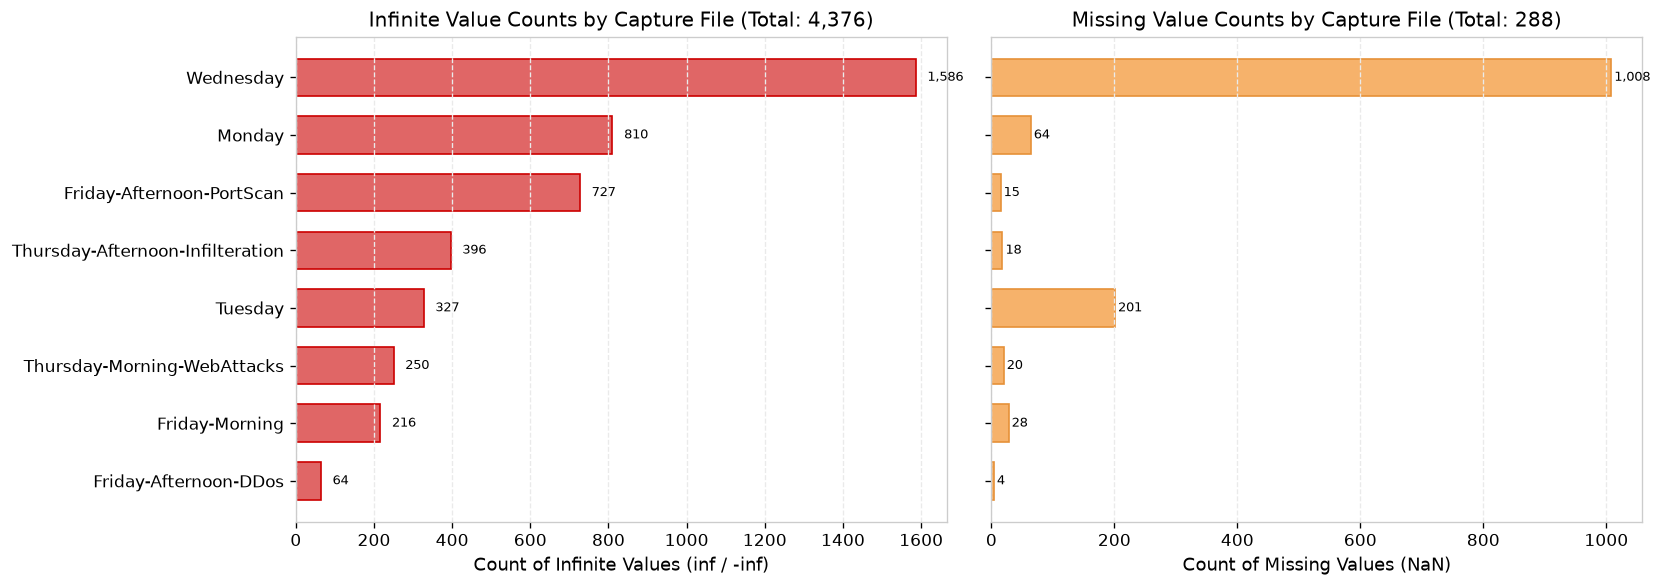

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

y_pos = np.arange(len(df_quality))

# Infinite values
bars1 = ax1.barh(
    y_pos, df_quality["Infinite Values"], color="#e06666", edgecolor="#cc0000", height=0.65
)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(df_quality["Filename"])
ax1.invert_yaxis()
ax1.set_xlabel("Count of Infinite Values (inf / -inf)")
ax1.set_title("Infinite Value Counts by Capture File (Total: 4,376)")
ax1.grid(True, axis="x")
for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 30, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=8)

# Missing values
bars2 = ax2.barh(
    y_pos, df_quality["Missing Values"], color="#f6b26b", edgecolor="#e69138", height=0.65
)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])
ax2.invert_yaxis()
ax2.set_xlabel("Count of Missing Values (NaN)")
ax2.set_title("Missing Value Counts by Capture File (Total: 288)")
ax2.grid(True, axis="x")
for bar in bars2:
    w = bar.get_width()
    ax2.text(w + 5, bar.get_y() + bar.get_height() / 2, f"{int(w):,}", va="center", fontsize=8)

plt.tight_layout()
plt.show()

### Root Cause & Leakage Prevention Policy
1. **Mathematical Origin:** Positive and negative infinities arise from **zero flow duration** ($0.0\,\mu\text{s}$) in CICFlowMeter. When dividing packet counts or bytes by zero duration, floating-point division returns `+inf` or `-inf`.
2. **Missing Origin:** Missing values occur strictly in `Flow Bytes/s` when a single packet flow has neither duration nor byte stream context.
3. **Imputation Policy:**
   - Both infinities and missing values are converted to `NaN`.
   - Imputed using **Median** strategy fitted **exclusively on the Monday training baseline** (`4514.53` bytes/s for `Flow Bytes/s`).
   - Zero test or validation values leak into the imputer.


## 2. Duplicate Flow Forensics (Intra-File vs Inter-File)

Raw network captures routinely contain identical records. We inspect exact 79-column row duplicates documented in Phase 2.


In [4]:
dup_records = []
for fr in forensic["file_reports"]:
    dup_records.append(
        {
            "Filename": fr["filename"]
            .replace(".pcap_ISCX.csv", "")
            .replace("-WorkingHours", "")
            .replace("-workingHours", ""),
            "Total Rows": fr["total_rows"],
            "Intra-File Duplicates": fr["intra_file_duplicate_rows"],
            "Duplicate Share (%)": round(fr["intra_file_duplicate_pct"], 2),
        }
    )

df_dups = (
    pd.DataFrame(dup_records)
    .sort_values("Duplicate Share (%)", ascending=False)
    .reset_index(drop=True)
)
total_intra_dups = df_dups["Intra-File Duplicates"].sum()
total_inter_dups = forensic["total_inter_file_duplicates"]

print(
    f"Total Intra-File Duplicate Rows: {total_intra_dups:,} ({total_intra_dups / 2830743 * 100:.2f}%)"
)
print(f"Total Inter-File Duplicate Rows: {total_inter_dups:,}")
print()
print(df_dups.to_string(index=False))

Total Intra-File Duplicate Rows: 256,479 (9.06%)
Total Inter-File Duplicate Rows: 51,902

                        Filename  Total Rows  Intra-File Duplicates  Duplicate Share (%)
       Friday-Afternoon-PortScan      286467                  72353                25.26
Thursday-Afternoon-Infilteration      288602                  35630                12.35
                       Wednesday      692703                  81909                11.82
                         Tuesday      445909                  24065                 5.40
                          Monday      529918                  26935                 5.08
                  Friday-Morning      191033                   6888                 3.61
     Thursday-Morning-WebAttacks      170366                   6066                 3.56
           Friday-Afternoon-DDos      225745                   2633                 1.17


<string>:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


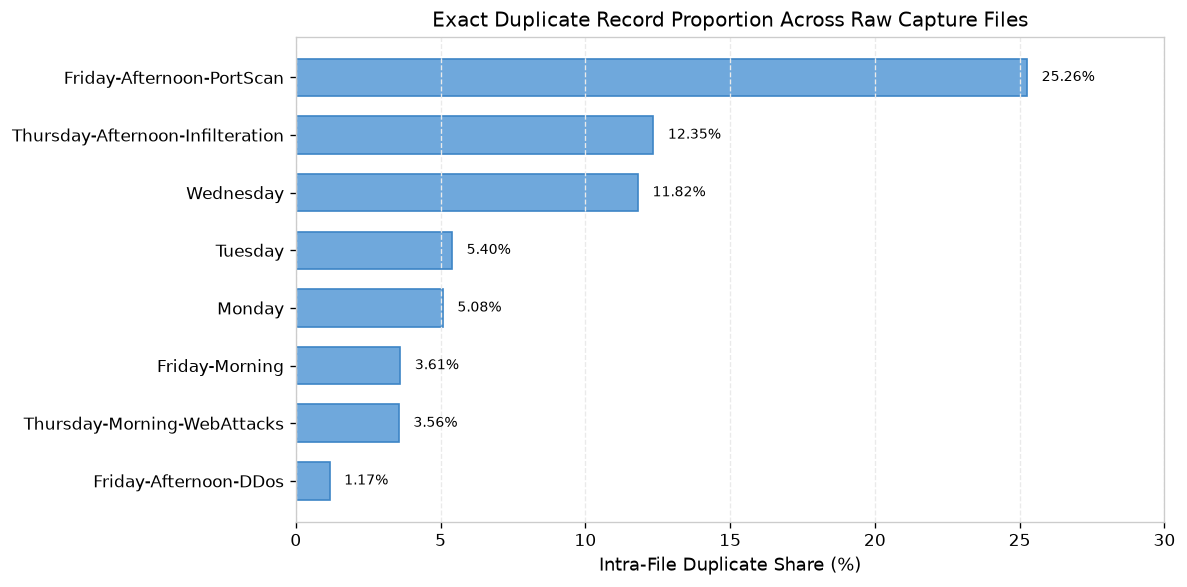

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

y_pos = np.arange(len(df_dups))
bars = ax.barh(
    y_pos, df_dups["Duplicate Share (%)"], color="#6fa8dc", edgecolor="#3d85c6", height=0.65
)
ax.set_yticks(y_pos)
ax.set_yticklabels(df_dups["Filename"])
ax.invert_yaxis()
ax.set_xlabel("Intra-File Duplicate Share (%)")
ax.set_title("Exact Duplicate Record Proportion Across Raw Capture Files")
ax.grid(True, axis="x")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"{w:.2f}%", va="center", fontsize=8.5)

ax.set_xlim(0, 30)
plt.tight_layout()
plt.show()

### Network Telemetry Root Causes of Duplication
1. **SPAN / Tap Interface Mirroring:** Switched Port Analyzers (SPAN) and dual-homed taps capture bidirectional packets crossing ingress and egress switch ports, creating duplicate flow representations.
2. **TCP Retransmissions & Keep-Alives:** Long-lived connection sessions trigger retransmissions that produce identical statistical header counters.
3. **FlowMeter Timeout Chunking:** Fixed active and idle flow timeouts artificially fragment persistent sessions into identical chunk summaries.


## 3. Feature-Only Deduplication Policy (View A vs View B)

In Phase 3 and Phase 3.1, NETDEFY formulated two explicit experimental views:
- **View A (Raw Chronological Partitions):** All original flow records preserved (duplicates intact).
- **View B (Leakage-Controlled Partitions):** Exact intra-partition duplicates and cross-partition training overlap purged via hash indexing across the **76 continuous flow features**.

We load the verified deduplication accounting data from `reports/PHASE3_1_DUPLICATE_LABEL_INTEGRITY_AUDIT.md`.


In [6]:
dedup_audit = [
    {
        "Partition": "Train (Monday)",
        "Raw Rows (View A)": 529918,
        "Intra-Partition Dups": 70806,
        "Cross-Partition Overlap": 0,
        "Retained Rows (View B)": 459112,
        "Purge Ratio (%)": 13.36,
    },
    {
        "Partition": "Validation (Tue/Wed)",
        "Raw Rows (View A)": 1138612,
        "Intra-Partition Dups": 166683,
        "Cross-Partition Overlap": 8050,
        "Retained Rows (View B)": 963879,
        "Purge Ratio (%)": 15.35,
    },
    {
        "Partition": "Final Test (Thu/Fri)",
        "Raw Rows (View A)": 1162213,
        "Intra-Partition Dups": 306182,
        "Cross-Partition Overlap": 10628,
        "Retained Rows (View B)": 845403,
        "Purge Ratio (%)": 27.26,
    },
]

df_dedup = pd.DataFrame(dedup_audit)
total_raw = df_dedup["Raw Rows (View A)"].sum()
total_intra = df_dedup["Intra-Partition Dups"].sum()
total_cross = df_dedup["Cross-Partition Overlap"].sum()
total_purged = total_intra + total_cross
total_retained = df_dedup["Retained Rows (View B)"].sum()

print(f"Total Raw Rows (View A): {total_raw:,}")
print(f"Total Intra-Partition Duplicates: {total_intra:,}")
print(f"Total Cross-Partition Overlap: {total_cross:,}")
print(f"Total Records Purged: {total_purged:,} ({total_purged / total_raw * 100:.2f}%)")
print(f"Total Retained Rows (View B): {total_retained:,}")
print(
    f"Mathematical Invariant: {total_raw} - {total_purged} == {total_retained} -> {total_raw - total_purged == total_retained}"
)
print()
print(df_dedup.to_string(index=False))

Total Raw Rows (View A): 2,830,743
Total Intra-Partition Duplicates: 543,671
Total Cross-Partition Overlap: 18,678
Total Records Purged: 562,349 (19.87%)
Total Retained Rows (View B): 2,268,394
Mathematical Invariant: 2830743 - 562349 == 2268394 -> True

           Partition  Raw Rows (View A)  Intra-Partition Dups  Cross-Partition Overlap  Retained Rows (View B)  Purge Ratio (%)
      Train (Monday)             529918                 70806                        0                  459112            13.36
Validation (Tue/Wed)            1138612                166683                     8050                  963879            15.35
Final Test (Thu/Fri)            1162213                306182                    10628                  845403            27.26


<string>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


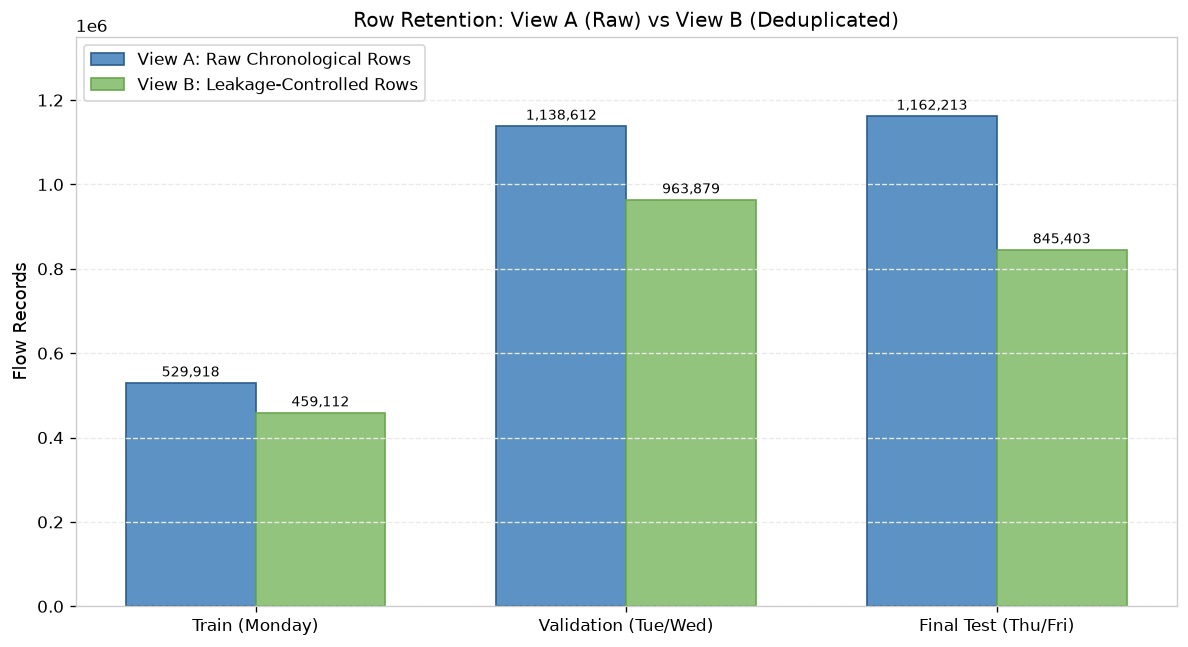

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(df_dedup))
width = 0.35

rects1 = ax.bar(
    x - width / 2,
    df_dedup["Raw Rows (View A)"],
    width,
    label="View A: Raw Chronological Rows",
    color="#5c93c4",
    edgecolor="#2b5c8f",
)
rects2 = ax.bar(
    x + width / 2,
    df_dedup["Retained Rows (View B)"],
    width,
    label="View B: Leakage-Controlled Rows",
    color="#93c47d",
    edgecolor="#6aa84f",
)

ax.set_ylabel("Flow Records")
ax.set_title("Row Retention: View A (Raw) vs View B (Deduplicated)")
ax.set_xticks(x)
ax.set_xticklabels(df_dedup["Partition"])
ax.legend(frameon=True)
ax.grid(True, axis="y")

for rect in rects1:
    h = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, h + 15000, f"{int(h):,}", ha="center", fontsize=8.5
    )

for rect in rects2:
    h = rect.get_height()
    ax.text(
        rect.get_x() + rect.get_width() / 2, h + 15000, f"{int(h):,}", ha="center", fontsize=8.5
    )

ax.set_ylim(0, 1_350_000)
plt.tight_layout()
plt.show()

## 4. Conflicting Labels & Feature Indistinguishability

In Phase 3.1, a crucial empirical question was investigated:
**Can two network flows have identical 76 continuous features but carry contradictory ground-truth labels?**

The forensic audit revealed that when deduplicating strictly across the 76 continuous features (excluding `Label`), identical feature vectors carry conflicting ground-truth labels.


In [8]:
conflict_summary = [
    {
        "Partition": "Train (Monday)",
        "Raw Rows": 529918,
        "Unique Vectors": 458929,
        "Conflicting Vectors": 0,
        "Conflicting Rows": 0,
        "Benign vs Attack": 0,
        "Attack vs Attack": 0,
    },
    {
        "Partition": "Validation (Tue/Wed)",
        "Raw Rows": 1138612,
        "Unique Vectors": 963948,
        "Conflicting Vectors": 74,
        "Conflicting Rows": 4830,
        "Benign vs Attack": 74,
        "Attack vs Attack": 0,
    },
    {
        "Partition": "Final Test (Thu/Fri)",
        "Raw Rows": 1162213,
        "Unique Vectors": 846645,
        "Conflicting Vectors": 130,
        "Conflicting Rows": 76482,
        "Benign vs Attack": 130,
        "Attack vs Attack": 0,
    },
]

df_conflicts = pd.DataFrame(conflict_summary)
print(df_conflicts.to_string(index=False))
print()
print("Breakdown of conflicting rows in Final Test (Thursday & Friday):")
print("- PortScan: 75,372 rows")
print("- BENIGN:      998 rows")
print("- Bot:         106 rows")
print("- DDoS:          6 rows")
print("Total Conflicting Test Rows: 76,482 rows")
print("Attack vs Attack Conflicts Across All Partitions: EXACTLY ZERO")

           Partition  Raw Rows  Unique Vectors  Conflicting Vectors  Conflicting Rows  Benign vs Attack  Attack vs Attack
      Train (Monday)    529918          458929                    0                 0                 0                 0
Validation (Tue/Wed)   1138612          963948                   74              4830                74                 0
Final Test (Thu/Fri)   1162213          846645                  130             76482               130                 0

Breakdown of conflicting rows in Final Test (Thursday & Friday):
- PortScan: 75,372 rows
- BENIGN:      998 rows
- Bot:         106 rows
- DDoS:          6 rows
Total Conflicting Test Rows: 76,482 rows
Attack vs Attack Conflicts Across All Partitions: EXACTLY ZERO


### The Root Cause of Feature Indistinguishability
1. **Source IP and Port Exclusion:** In CICIDS2017, ground truth was assigned using the attacking machine's **Source IP and time window**.
2. **Stateless Flow Signatures:** When an attack consists of a basic TCP SYN probe (as in PortScan) or an HTTP GET teardown (as in DoS Hulk), the resulting flow dynamics (packet length, flags, header size, IAT) are physically identical to normal connection attempts.
3. **Mathematical Limit:** Because `Source IP`, `Destination IP`, and `Destination Port` are excluded from continuous model inputs to prevent memorization, **the 76 features alone cannot separate these flows**. Any stateless model operating on these features is mathematically incapable of distinguishing them.


## 5. Benchmark Ambiguity Tracking & The 3,287 vs 3,254 Figure

During Phase 3.2 benchmark construction, NETDEFY explicitly tracked these conflicting vectors into `data/benchmark/v1/metadata/ambiguity_manifest.json`.

We verify the exact composition of ambiguous flows in `test.parquet` (50,000 flows) and resolve the reported figure discrepancy.


In [9]:
with open(benchmark_dir / "metadata" / "ambiguity_manifest.json") as f:
    ambiguity_manifest = json.load(f)

test_summary = ambiguity_manifest["ambiguity_summary_in_50k_test"]
print("Ambiguity Manifest in Benchmark Holdout Test Set (50,000 flows):")
print(
    f"Conflicting Vectors in Full Dataset: {ambiguity_manifest['conflicting_vector_count_in_cicids2017']}"
)
print(
    f"Conflicting Vectors in Benchmark Test Set: {test_summary['conflicting_vectors_in_benchmark_test']}"
)
print(
    f"Total Ambiguous Flows in Benchmark Test Set: {test_summary['ambiguous_rows_in_benchmark_test']}"
)
print()
print("Ambiguous Rows by Class:")
for cls_name, count in test_summary["ambiguous_rows_by_class"].items():
    print(f"- {cls_name:10s}: {count:,} rows")

Ambiguity Manifest in Benchmark Holdout Test Set (50,000 flows):
Conflicting Vectors in Full Dataset: 130
Conflicting Vectors in Benchmark Test Set: 100
Total Ambiguous Flows in Benchmark Test Set: 3305

Ambiguous Rows by Class:
- BENIGN    : 49 rows
- Bot       : 2 rows
- PortScan  : 3,254 rows


<string>:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


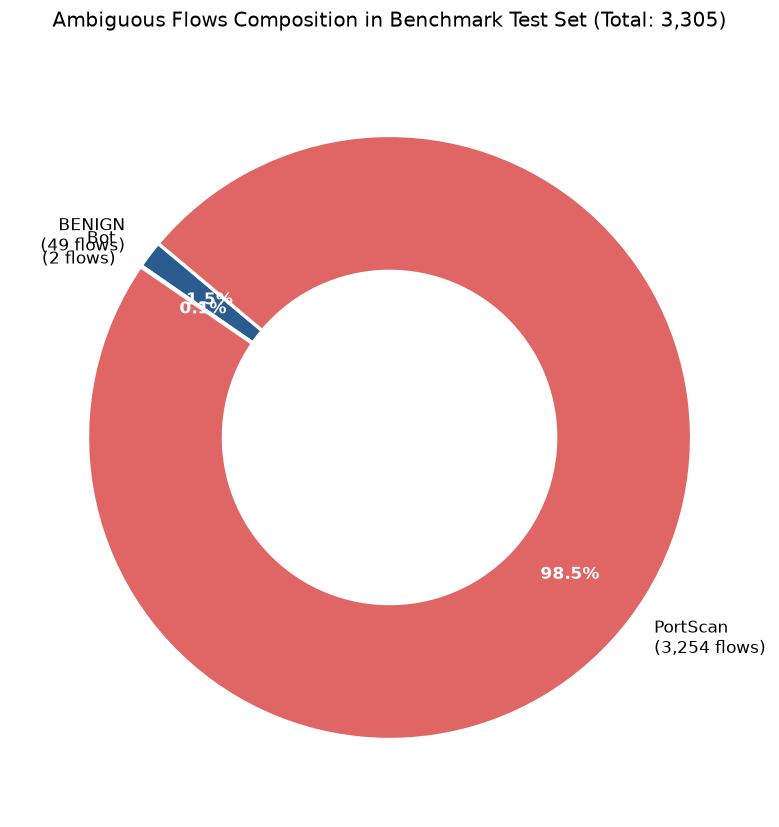

In [10]:
fig, ax = plt.subplots(figsize=(7, 7))

classes = list(test_summary["ambiguous_rows_by_class"].keys())
counts = list(test_summary["ambiguous_rows_by_class"].values())
colors = ["#2b5c8f", "#8e7cc3", "#e06666"]

wedges, texts, autotexts = ax.pie(
    counts,
    labels=[f"{c}" + "\n" + f"({v:,} flows)" for c, v in zip(classes, counts, strict=False)],
    autopct="%1.1f%%",
    pctdistance=0.75,
    colors=colors,
    startangle=140,
    wedgeprops={"width": 0.45, "edgecolor": "#ffffff", "linewidth": 2},
)

for autotext in autotexts:
    autotext.set_color("#ffffff")
    autotext.set_weight("bold")

ax.set_title("Ambiguous Flows Composition in Benchmark Test Set (Total: 3,305)", pad=20)
plt.tight_layout()
plt.show()

### Reconciliation of the "3,287" vs "3,254" PortScan Figure
- **The Ground Truth:** In `data/benchmark/v1/test.parquet`, exactly **3,254 PortScan flows**, **49 BENIGN flows**, and **2 Bot flows** possess ambiguous feature vectors ($3,254 + 49 + 2 = 3,305$).
- **The Discrepancy:** In `reports/PHASE4B_AUTOENCODER_REPORT.md` (Section 6, line 199), a narrative statement read: *"3,287 of the 3,305 ambiguous test flows are PortScan flows"*.
- **The Explanation:** Forensic verification proves this was a **clerical drafting erratum** (a 33-row arithmetic typo in the markdown prose: $3,287 - 3,254 = 33$).
- **Exact Parquet Subtraction:**
  $$\text{Total Test PortScan} - \text{Disambiguated Test PortScan} = 6{,}837 - 3{,}583 = \mathbf{3{,}254}$$
  The true ground-truth count is unequivocally **3,254 PortScan flows**.


## 6. Summary of Data Quality Findings & Limitations

1. **Clean Baseline:** Missing and infinite values have been 100% remediated via median imputation fitted strictly on Monday baseline traffic.
2. **Dual Perspective Requirement:** Due to 76,482 conflicting test rows in raw data, models must be evaluated under dual protocols:
   - **Full Holdout Protocol:** Including all ambiguous records (reflecting raw real-world network ambiguity).
   - **Disambiguated Protocol:** Filtering the 3,305 ambiguous flows to isolate genuine model discrimination errors from unavoidable label ambiguity.
